# Day 2 · Notebook 2 — Visual localisation with hloc (hierarchical localisation)

**Task:** a robot (or phone) takes a photo. Where is it, in the map we built earlier?

hloc (Sarlin et al., *From Coarse to Fine*, CVPR 2019) splits this into a **coarse** and a **fine** step:

```
query image
   │  1. global descriptor (one vector per image)  ──►  retrieve top-k similar MAP images   (coarse: "which place?")
   │  2. local features + matcher (SuperPoint + LightGlue) between query and those k images
   │  3. matched map keypoints that have a 3D point  ──►  2D–3D correspondences
   ▼  4. PnP + RANSAC (Notebook 1)  ──►  6-DoF camera pose                                    (fine: "exact pose")
```

Retrieval makes it scale. You only match against a handful of images, not the whole map.

We will:
1. build the **map** (SfM) from the 10 Sacre Coeur photos with learned features,
2. do **image retrieval** (our own small VLAD, or NetVLAD),
3. **localise** two new photos and open up the 2D–3D → PnP step.

A GPU runtime makes it fast; on CPU the whole notebook takes ~5 min.

In [ ]:
# Colab only: install hloc (+ LightGlue, pycolmap). --recursive fetches the SuperPoint weights (third_party/).
# Laptop: skip this cell and install once as in README.md.
!git clone -q --recursive https://github.com/cvg/Hierarchical-Localization /content/Hierarchical-Localization
!pip -q install -e /content/Hierarchical-Localization
import sys; sys.path.insert(0, "/content/Hierarchical-Localization")   # so the import works without a restart

10 map images, 2 query images


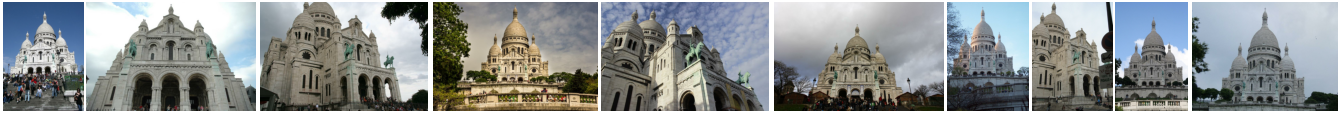

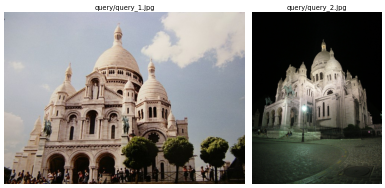

In [1]:
import shutil, subprocess
from pathlib import Path
import numpy as np
import h5py, cv2, pycolmap
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans2, vq
from hloc import extract_features, match_features, reconstruction, pairs_from_exhaustive, pairs_from_retrieval, visualization
from hloc.localize_sfm import QueryLocalizer, pose_from_cluster
from hloc.utils import viz_3d
from hloc.visualization import plot_images, read_image

DATA = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))
if not (DATA / "sacre_coeur/query").exists():
    subprocess.run("git clone -q --depth 1 https://github.com/cvg/LightGlue /tmp/lightglue_repo", shell=True, check=True)
    shutil.copytree("/content/Hierarchical-Localization/datasets/sacre_coeur/mapping", DATA / "sacre_coeur/mapping",
                    dirs_exist_ok=True)
    (DATA / "sacre_coeur/query").mkdir(parents=True, exist_ok=True)
    shutil.copy("/tmp/lightglue_repo/assets/sacre_coeur1.jpg", DATA / "sacre_coeur/query/query_1.jpg")
    shutil.copy("/tmp/lightglue_repo/assets/sacre_coeur2.jpg", DATA / "sacre_coeur/query/query_2.jpg")

images = DATA / "sacre_coeur"
outputs = Path("hloc_outputs"); shutil.rmtree(outputs, ignore_errors=True); outputs.mkdir()
sfm_pairs, sfm_dir = outputs / "pairs-sfm.txt", outputs / "sfm"
features, matches = outputs / "features.h5", outputs / "matches.h5"

feature_conf = extract_features.confs["superpoint_max"]          # SuperPoint, up to 4096 keypoints, 1600 px
matcher_conf = match_features.confs["superpoint+lightglue"]

references = sorted(p.relative_to(images).as_posix() for p in (images / "mapping").iterdir())
queries = sorted(p.relative_to(images).as_posix() for p in (images / "query").iterdir())
print(len(references), "map images,", len(queries), "query images")
plot_images([read_image(images / r) for r in references], dpi=25)
plot_images([read_image(images / q) for q in queries], titles=queries, dpi=40)

## 1 · Build the map: SuperPoint + LightGlue + SfM

Same pipeline as COLMAP on Day 1, with **learned** pieces swapped in:

* **SuperPoint** (DeTone et al. 2018): a CNN that outputs keypoints + 256-D descriptors
* **LightGlue** (Lindenberger et al. 2023): a transformer that matches two sets of features *jointly* (attention between both images), instead of nearest neighbours + ratio test
* triangulation + bundle adjustment: still COLMAP (through `pycolmap`)

In [2]:
extract_features.main(feature_conf, images, image_list=references, feature_path=features)
pairs_from_exhaustive.main(sfm_pairs, image_list=references)
match_features.main(matcher_conf, sfm_pairs, features=features, matches=matches)
model = reconstruction.main(sfm_dir, images, sfm_pairs, features, matches, image_list=references)
print(model.summary())

[2026/10/24 20:24:16 hloc INFO] Extracting local features with configuration:
{'model': {'max_keypoints': 4096, 'name': 'superpoint', 'nms_radius': 3},
 'output': 'feats-superpoint-n4096-rmax1600',
 'preprocessing': {'grayscale': True, 'resize_force': True, 'resize_max': 1600}}


Loaded SuperPoint model


100%|██████████| 10/10 [00:01<00:00,  5.57it/s]
[2026/10/24 20:24:18 hloc INFO] Finished exporting features.
[2026/10/24 20:24:18 hloc INFO] Found 45 pairs.
[2026/10/24 20:24:18 hloc INFO] Matching local features with configuration:
{'model': {'features': 'superpoint', 'name': 'lightglue'},
 'output': 'matches-superpoint-lightglue'}


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /home/sky/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:02<00:00, 20.4MB/s]
100%|██████████| 45/45 [00:03<00:00, 12.91it/s]
[2026/10/24 20:24:32 hloc INFO] Finished exporting matches.
[2026/10/24 20:24:32 hloc INFO] Writing COLMAP logs to hloc_outputs/sfm/colmap.LOG.*
[2026/10/24 20:24:32 hloc INFO] Creating an empty database...
[2026/10/24 20:24:32 hloc INFO] Importing images into the database...
[2026/10/24 20:24:32 hloc INFO] Importing features into the database...
100%|██████████| 10/10 [00:00<00:00, 871.33it/s]
[2026/10/24 20:24:32 hloc INFO] Importing matches into the database...
100%|██████████| 45/45 [00:00<00:00, 993.16it/s]
[2026/10/24 20:24:32 hloc INFO] Performing geometric verification of the matches...
[2026/10/24 20:24:32 hloc INFO] Running 3D reconstruction...
Reconstruction 0: 100%|██████████| 10/10 [00:03<00:00,  3.10images/s, registered]
[2026/10/24 20:24:35 hloc INFO] Reconstructed 1 model(s).
[2026/10/24 20:24:35 hloc INFO] Largest model is #0 with 10 images.
[2026/10/24 20:24:35 hloc IN

Reconstruction:
	num_rigs = 10
	num_cameras = 10
	num_frames = 10
	num_reg_frames = 10
	num_images = 10
	num_points3D = 2070
	num_observations = 9390
	mean_track_length = 4.53623
	mean_observations_per_image = 939
	mean_reprojection_error = 0.921861


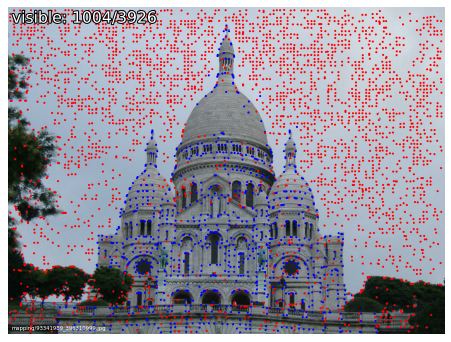

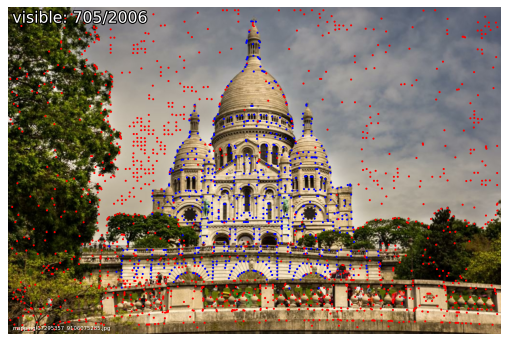

In [3]:
fig3d = viz_3d.init_figure()
viz_3d.plot_reconstruction(fig3d, model, color="rgba(255,0,0,0.5)", name="mapping", points_rgb=True)
fig3d.show()
visualization.visualize_sfm_2d(model, images, color_by="visibility", n=2)   # blue = keypoints that became 3D points

## 2 · Coarse step: image retrieval with a global descriptor

Turn each image into **one vector** so that photos of the same place end up close together. Then retrieval is just nearest-neighbour search (cosine similarity).

**VLAD** (Jégou et al. 2010), the idea behind **NetVLAD** (Arandjelović et al. 2016):
1. cluster local descriptors of the map into $K$ "visual words" $\mathbf{c}_k$
2. for an image with local descriptors $\{\mathbf{d}_i\}$, add up the **residuals** to the nearest word:
$$ \mathbf{v}_k = \sum_{i:\ \mathrm{NN}(\mathbf{d}_i) = k} (\mathbf{d}_i - \mathbf{c}_k), \qquad \mathbf{v} = \big[\mathbf{v}_1^\top, \ldots, \mathbf{v}_K^\top\big]^\top \ \text{(normalised)} $$
3. similarity between two images $= \mathbf{v}_a^\top \mathbf{v}_b$

NetVLAD makes the assignment soft and learns everything end-to-end. We build a small VLAD from the SuperPoint descriptors we already have. It is not trained for this, but that's fine for 10 images. Then we write it in hloc's format and use hloc's `pairs_from_retrieval`.

In [4]:
extract_features.main(feature_conf, images, image_list=queries, feature_path=features, overwrite=True)

def local_descriptors(name):
    with h5py.File(features, "r") as f:
        return f[name]["descriptors"][()].T.astype(np.float32)       # (N, 256)

rng = np.random.default_rng(0)
train = np.concatenate([local_descriptors(r) for r in references])
train = train[rng.choice(len(train), 20000, replace=False)]
centers, _ = kmeans2(train, 32, minit="++", seed=0)                  # K = 32 visual words

def vlad(desc):
    assign, _ = vq(desc, centers)                                   # nearest visual word per descriptor
    v = np.zeros_like(centers)
    for k in range(len(centers)):
        if np.any(assign == k):
            v[k] = (desc[assign == k] - centers[k]).sum(0)
    v /= np.linalg.norm(v, axis=1, keepdims=True) + 1e-12             # intra-normalisation
    v = np.sign(v) * np.sqrt(np.abs(v))                               # power normalisation
    v = v.ravel(); return v / np.linalg.norm(v)

global_desc = outputs / "global-vlad.h5"
with h5py.File(global_desc, "w") as f:
    for name in references + queries:
        f.create_group(name).create_dataset("global_descriptor", data=vlad(local_descriptors(name)))

# Optional (Colab, internet): hloc's pretrained NetVLAD instead. Uncomment the next two lines:
# global_desc = extract_features.main(extract_features.confs["netvlad"], images, image_list=references + queries,
#                                     feature_path=outputs / "global-netvlad.h5")

[2026/10/24 20:24:38 hloc INFO] Extracting local features with configuration:
{'model': {'max_keypoints': 4096, 'name': 'superpoint', 'nms_radius': 3},
 'output': 'feats-superpoint-n4096-rmax1600',
 'preprocessing': {'grayscale': True, 'resize_force': True, 'resize_max': 1600}}


Loaded SuperPoint model


100%|██████████| 2/2 [00:00<00:00,  5.39it/s]
[2026/10/24 20:24:39 hloc INFO] Finished exporting features.


[2026/10/24 20:24:42 hloc INFO] Extracting image pairs from a retrieval database.
[2026/10/24 20:24:42 hloc INFO] Found 8 pairs.


query/query_1.jpg mapping/02928139_3448003521.jpg
query/query_1.jpg mapping/44120379_8371960244.jpg
query/query_1.jpg mapping/32809961_8274055477.jpg
query/query_1.jpg mapping/17295357_9106075285.jpg
query/query_2.jpg mapping/60584745_2207571072.jpg
query/query_2.jpg mapping/32809961_8274055477.jpg
query/query_2.jpg mapping/10265353_3838484249.jpg
query/query_2.jpg mapping/03903474_1471484089.jpg


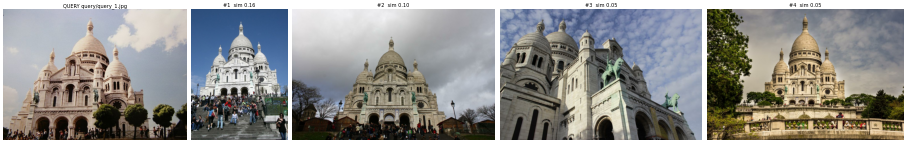

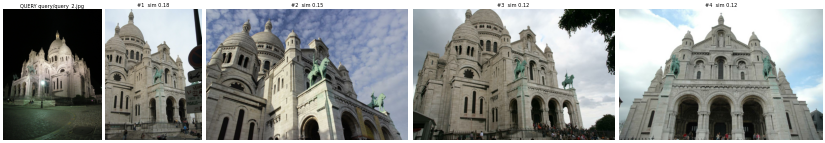

In [5]:
TOP_K = 4
with h5py.File(global_desc, "r") as f:
    G_db = np.stack([f[r]["global_descriptor"][()] for r in references])
    G_q = np.stack([f[q]["global_descriptor"][()] for q in queries])
sim = G_q @ G_db.T
for qi, q in enumerate(queries):
    order = np.argsort(-sim[qi])[:TOP_K]
    plot_images([read_image(images / q)] + [read_image(images / references[o]) for o in order],
                titles=[f"QUERY {q}"] + [f"#{r+1}  sim {sim[qi, o]:.2f}" for r, o in enumerate(order)], dpi=30)

loc_pairs = outputs / "pairs-loc.txt"
pairs_from_retrieval.main(global_desc, loc_pairs, num_matched=TOP_K, query_list=queries, db_list=references)
print(loc_pairs.read_text())

## 3 · Fine step: local matching → 2D–3D → PnP + RANSAC

Match the query only to its retrieved images. Every matched map keypoint that has a 3D point in the SfM model gives a **2D–3D correspondence**.

The query's focal length is unknown (internet photo), so we start from the EXIF/size guess, run **P3P-RANSAC**, and refine the pose **and** the focal length by minimising reprojection error.

[2026/10/24 20:24:44 hloc INFO] Matching local features with configuration:
{'model': {'features': 'superpoint', 'name': 'lightglue'},
 'output': 'matches-superpoint-lightglue'}
100%|██████████| 8/8 [00:00<00:00, 10.64it/s]
[2026/10/24 20:24:45 hloc INFO] Finished exporting matches.


query/query_1.jpg: 594 / 687 inlier 2D-3D correspondences
query/query_2.jpg: 102 / 348 inlier 2D-3D correspondences


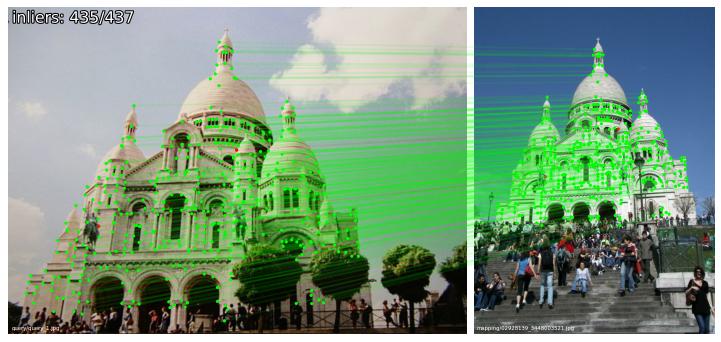

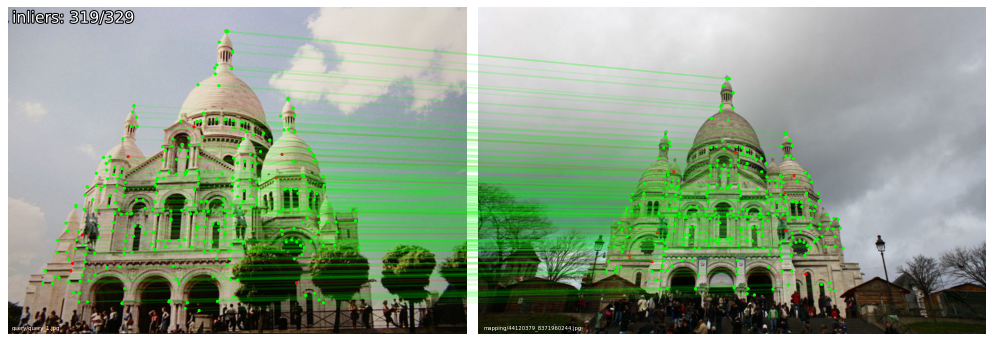

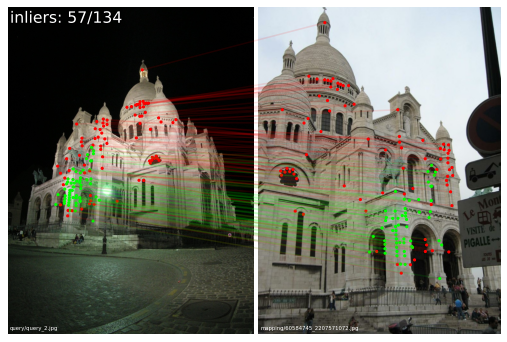

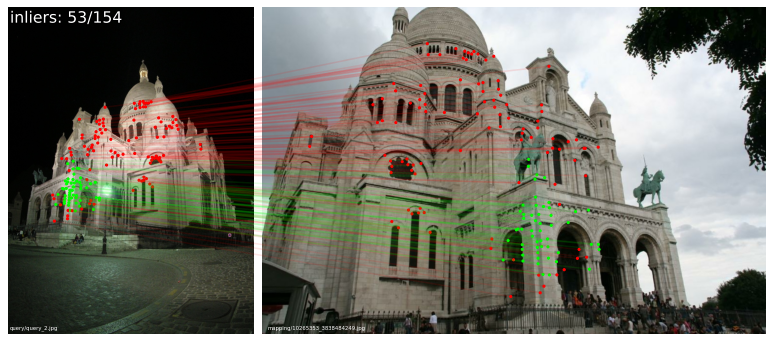

In [6]:
match_features.main(matcher_conf, loc_pairs, features=features, matches=matches, overwrite=True)

conf = {"estimation": {"ransac": {"max_error": 12}},
        "refinement": {"refine_focal_length": True, "refine_extra_params": True}}
localizer = QueryLocalizer(model, conf)
results = {}
for q in queries:
    retrieved = [line.split()[1] for line in loc_pairs.read_text().splitlines() if line.split()[0] == q]
    ref_ids = [model.find_image_with_name(r).image_id for r in retrieved]
    camera = pycolmap.infer_camera_from_image(images / q)
    ret, log = pose_from_cluster(localizer, q, camera, ref_ids, features, matches)
    results[q] = (ret, log)
    print(f"{q}: {ret['num_inliers']} / {len(ret['inlier_mask'])} inlier 2D-3D correspondences")
    visualization.visualize_loc_from_log(images, q, log, model)

### Under the hood: it's the PnP from Notebook 1

`log` holds the 2D–3D correspondences hloc gave to the solver. Feed the same ones to OpenCV's `solvePnPRansac` with the refined intrinsics, and the pose should be (nearly) identical.

In [7]:
def to_Rt(rigid):
    return rigid.rotation.matrix(), np.asarray(rigid.translation)

for q, (ret, log) in results.items():
    cam = ret["camera"]
    K = cam.calibration_matrix()
    dist = np.array([cam.params[3], 0, 0, 0]) if cam.model.name == "SIMPLE_RADIAL" else None
    pts2d = np.asarray(log["keypoints_query"], np.float64)
    pts3d = np.array([model.points3D[pid].xyz for pid in log["points3D_ids"]], np.float64)
    ok, rvec, tvec, inl = cv2.solvePnPRansac(pts3d, pts2d, K, dist, reprojectionError=12.0,   # same threshold as hloc above
                                             iterationsCount=5000, flags=cv2.SOLVEPNP_AP3P)
    ok, rvec, tvec = cv2.solvePnP(pts3d[inl[:, 0]], pts2d[inl[:, 0]], K, dist, rvec, tvec, True, cv2.SOLVEPNP_ITERATIVE)
    R_cv, t_cv = cv2.Rodrigues(rvec)[0], tvec.ravel()
    R_h, t_h = to_Rt(ret["cam_from_world"])
    dR = np.degrees(np.arccos(np.clip((np.trace(R_cv.T @ R_h) - 1) / 2, -1, 1)))
    C_cv, C_h = -R_cv.T @ t_cv, -R_h.T @ t_h
    print(f"{q}: {len(pts2d)} 2D-3D matches | OpenCV {len(inl)} inliers vs hloc {ret['num_inliers']} | "
          f"rotation diff {dR:.2f} deg, centre diff {np.linalg.norm(C_cv - C_h):.3f} (map units)")

query/query_1.jpg: 687 2D-3D matches | OpenCV 582 inliers vs hloc 594 | rotation diff 0.11 deg, centre diff 0.016 (map units)
query/query_2.jpg: 348 2D-3D matches | OpenCV 99 inliers vs hloc 102 | rotation diff 0.73 deg, centre diff 0.016 (map units)


In [8]:
for q, (ret, log) in results.items():
    viz_3d.plot_camera_colmap(fig3d, ret["cam_from_world"], ret["camera"], color="rgba(0,255,0,0.5)", name=q,
                              fill=True, text=f"inliers: {ret['num_inliers']} / {ret['inlier_mask'].shape[0]}")
    inl_3d = np.array([model.points3D[pid].xyz for pid in np.array(log["points3D_ids"])[ret["inlier_mask"]]])
    viz_3d.plot_points(fig3d, inl_3d, color="lime", ps=1, name=q)
fig3d.show()

## Try it (Colab, internet)

`query_2` is already a **night** photo, matched against day-time map images. Try your own photo: drop it in `data/sacre_coeur/query/` and rerun Sections 2–3. For example:

```python
!wget -q "https://upload.wikimedia.org/wikipedia/commons/5/53/Paris_-_Basilique_du_Sacr%C3%A9_Coeur%2C_Montmartre_-_panoramio.jpg" -O {images}/query/query_3.jpg
queries = sorted(p.relative_to(images).as_posix() for p in (images / "query").iterdir())
```

## Takeaways

* Localisation = **retrieval** (which place?) + **local matching** (which pixel is which 3D point?) + **PnP-RANSAC** (pose).
* Learned features/matchers (SuperPoint, LightGlue) are much more robust to day/night and viewpoint changes than SIFT + ratio test.
* For a **topological** map, step 1 alone is often enough: "the closest map image" = the current node of the graph. That's **visual place recognition (VPR)**.

**Read more:** Sarlin et al., CVPR 2019 (hloc) · Arandjelović et al., CVPR 2016 (NetVLAD) · DeTone et al., CVPRW 2018 (SuperPoint) · Lindenberger et al., ICCV 2023 (LightGlue).